In [1]:
import pandas as pd

df = pd.read_csv("obesity.csv")

df.head()


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [14]:
print(df.isna().mean() * 100) 

X = df.drop(columns=["NObeyesdad"])
y = df["NObeyesdad"]

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
#non ci sono dati mancanti quindi non è necessario imputare

lb = LabelEncoder()
y_encoded = lb.fit_transform(y)

print(df.head())
print(df.info())

X_train,X_test,y_train,y_test = train_test_split(X,y_encoded,stratify=y_encoded, test_size=0.15)

cat_features = X_train.select_dtypes(include=["object","string","bool"]).columns
num_features = X_train.select_dtypes(include=["number"]).columns

cat_pipe=Pipeline(steps=[
    ("encoder", OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop="first"))
])

num_pipe=Pipeline(steps=[
    ("scaler", StandardScaler())
])


preprocessor = ColumnTransformer(transformers=[
    ("cat", cat_pipe, cat_features),
    ("num", num_pipe, num_features)
])

preprocessor.set_output(transform="pandas")

preprocessor.fit(X_train, y_train)
X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)






Gender                            0.0
Age                               0.0
Height                            0.0
Weight                            0.0
family_history_with_overweight    0.0
FAVC                              0.0
FCVC                              0.0
NCP                               0.0
CAEC                              0.0
SMOKE                             0.0
CH2O                              0.0
SCC                               0.0
FAF                               0.0
TUE                               0.0
CALC                              0.0
MTRANS                            0.0
NObeyesdad                        0.0
dtype: float64
   Gender   Age  Height  Weight family_history_with_overweight FAVC  FCVC  \
0  Female  21.0    1.62    64.0                            yes   no   2.0   
1  Female  21.0    1.52    56.0                            yes   no   3.0   
2    Male  23.0    1.80    77.0                            yes   no   2.0   
3    Male  27.0    1.80    87.0

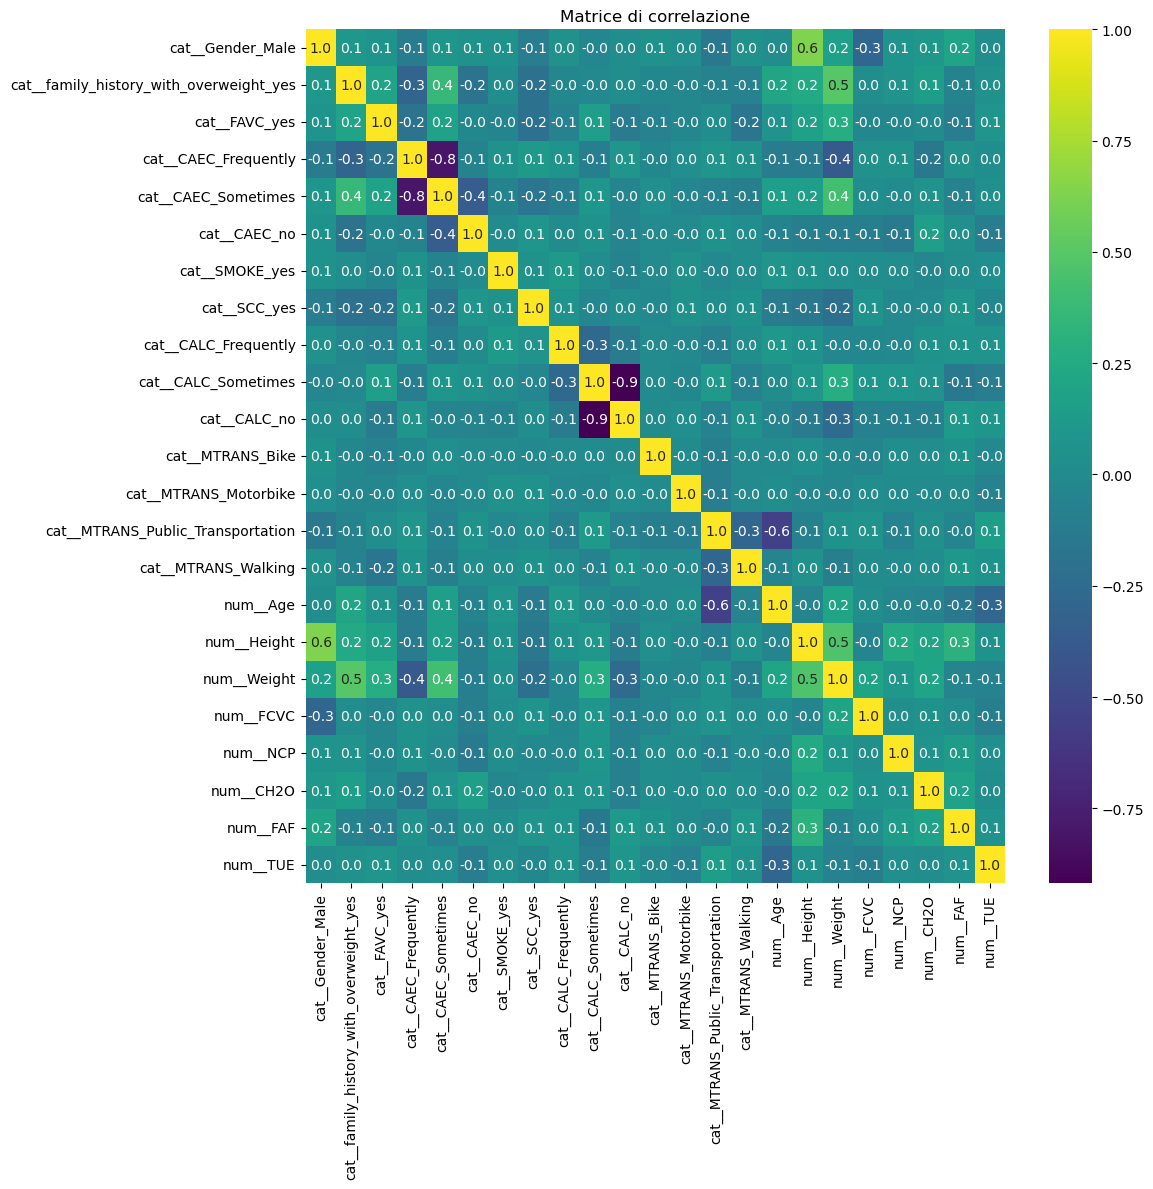

In [15]:
# Analisi matrice di correlazione
import seaborn as sns
import matplotlib.pyplot as plt

corr = X_train_processed.corr()


plt.figure(figsize=(12,12))
sns.heatmap(corr, fmt=".1f", annot=True, cmap="viridis")
plt.title("Matrice di correlazione")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
to_drop = [column for column in upper.columns if any(upper[column] > 0.80)]

X_train_processed = X_train_processed.drop(columns=to_drop)
X_test_processed=X_test_processed.drop(columns=to_drop)



In [21]:
df["NObeyesdad"].nunique()

7

In [22]:
# Selezione features

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(solver="svd", n_components=6)
lda.fit(X_train_processed, y_train)
X_train_fin = lda.transform(X_train_processed)
X_test_fin = lda.transform(X_test_processed)